In [2]:
# ============================================================
# সেল ০: ডেটাসেট আপলোড ও Extract
# ============================================================
from google.colab import files
import zipfile
import glob
import os

print("📤 তিনটি ZIP ফাইল আপলোড করুন:")
uploaded = files.upload()

for filename in uploaded.keys():
    if filename.endswith('.zip'):
        with zipfile.ZipFile(filename, 'r') as zip_ref:
            zip_ref.extractall('.')
        print(f"✅ {filename} extracted!")

COMPAS_PATH = glob.glob('**/compas-scores-two-years.csv', recursive=True)[0]
GERMAN_PATH = glob.glob('**/german.data', recursive=True)[0]
ADULT_PATH = glob.glob('**/adult.data', recursive=True)[0]

print(f"✅ COMPAS: {COMPAS_PATH}")
print(f"✅ German: {GERMAN_PATH}")
print(f"✅ Adult: {ADULT_PATH}")

📤 তিনটি ZIP ফাইল আপলোড করুন:


Saving adult.zip to adult.zip
Saving compas-analysis-master.zip to compas-analysis-master.zip
Saving statlog+german+credit+data.zip to statlog+german+credit+data.zip
✅ adult.zip extracted!
✅ compas-analysis-master.zip extracted!
✅ statlog+german+credit+data.zip extracted!
✅ COMPAS: compas-analysis-master/compas-scores-two-years.csv
✅ German: german.data
✅ Adult: adult.data


In [3]:
# ============================================================
# সেল ১: লাইব্রেরি + Global Configuration
# ============================================================
!pip install shap xgboost -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, r2_score
from scipy.stats import ttest_rel

# ============================================================
# GLOBAL CONFIGURATION
# ============================================================
CONFIG = {
    "random_seeds": [42, 123, 2024],  # Multiple seeds for robust statistics
    "epsilon": 0.15,                   # Perturbation budget
    "random_search_iterations": 30,    # Attack budget T
    "pgd_iterations": 20,
    "pgd_alpha": 0.01,
    "pgd_fd_step": 0.001,
    "pec_lambda": 0.5,
    "pec_eta": 0.01,
    "pec_mc_samples": 10,
    "n_attack_samples": 50,
}

print("✅ Libraries loaded!")
print(f"✅ Global CONFIG set: {CONFIG}")

✅ Libraries loaded!
✅ Global CONFIG set: {'random_seeds': [42, 123, 2024], 'epsilon': 0.15, 'random_search_iterations': 30, 'pgd_iterations': 20, 'pgd_alpha': 0.01, 'pgd_fd_step': 0.001, 'pec_lambda': 0.5, 'pec_eta': 0.01, 'pec_mc_samples': 10, 'n_attack_samples': 50}


In [4]:
# ============================================================
# সেল ২: Data Loading + Preprocessing (Data Leakage FIXED)
# ============================================================

def load_compas(path, random_state=42):
    """Load and preprocess COMPAS dataset. No data leakage."""
    df = pd.read_csv(path)
    features = ['age', 'sex', 'race', 'priors_count', 'juv_fel_count',
                'juv_misd_count', 'juv_other_count', 'c_charge_degree']
    target = 'two_year_recid'

    df = df[features + [target]].dropna()
    df = df[df[target].isin([0, 1])]
    df = df[df['race'].isin(['African-American', 'Caucasian', 'Hispanic', 'Other'])]

    cat_cols = ['sex', 'race', 'c_charge_degree']
    num_cols = ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count']

    # STEP 1: Split FIRST
    X_raw = df[features]
    y_raw = df[target].values
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_raw, y_raw, test_size=0.3, random_state=random_state, stratify=y_raw
    )

    # STEP 2: Fit on TRAIN ONLY
    preprocessor = ColumnTransformer([
        ('num', MinMaxScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ])
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    feat_names = num_cols + list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
    sensitive_indices = [i for i, name in enumerate(feat_names) if 'race' in name.lower()]
    non_sensitive = [i for i in range(len(feat_names)) if i not in sensitive_indices]

    return X_train, X_test, y_train, y_test, feat_names, sensitive_indices, non_sensitive


def load_german(path, random_state=42):
    """Load and preprocess German Credit dataset. No data leakage."""
    columns = ['checking_account', 'duration', 'credit_history', 'purpose',
               'credit_amount', 'savings', 'employment', 'installment_rate',
               'personal_status', 'debtors', 'residence', 'property', 'age',
               'installment_plans', 'housing', 'existing_credits', 'job',
               'dependents', 'telephone', 'foreign_worker', 'class']

    df = pd.read_csv(path, sep=' ', names=columns)
    df['class'] = df['class'] - 1

    features = ['age', 'credit_amount', 'duration', 'installment_rate',
                'residence', 'existing_credits', 'dependents', 'checking_account',
                'credit_history', 'purpose', 'savings', 'employment',
                'personal_status', 'housing', 'job']
    target = 'class'

    num_cols = ['age', 'credit_amount', 'duration', 'installment_rate',
                'residence', 'existing_credits', 'dependents']
    cat_cols = ['checking_account', 'credit_history', 'purpose', 'savings',
                'employment', 'personal_status', 'housing', 'job']

    # STEP 1: Split FIRST
    X_raw = df[features]
    y_raw = df[target].values
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_raw, y_raw, test_size=0.3, random_state=random_state, stratify=y_raw
    )

    # STEP 2: Fit on TRAIN ONLY
    preprocessor = ColumnTransformer([
        ('num', MinMaxScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ])
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    feat_names = num_cols + list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
    sensitive_indices = [feat_names.index('age')]
    non_sensitive = [i for i in range(len(feat_names)) if i not in sensitive_indices]

    return X_train, X_test, y_train, y_test, feat_names, sensitive_indices, non_sensitive


def load_adult(path, random_state=42):
    """Load and preprocess Adult Census dataset. No data leakage."""
    columns = ['age', 'workclass', 'fnlwgt', 'education', 'education_num',
               'marital_status', 'occupation', 'relationship', 'race', 'sex',
               'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

    df = pd.read_csv(path, names=columns, skipinitialspace=True, na_values='?').dropna()
    df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})
    df = df.iloc[:5000]  # Subset for speed

    features = ['age', 'workclass', 'education', 'education_num', 'marital_status',
                'occupation', 'relationship', 'race', 'sex', 'capital_gain',
                'capital_loss', 'hours_per_week']
    target = 'income'

    num_cols = ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
    cat_cols = ['workclass', 'education', 'marital_status', 'occupation',
                'relationship', 'race', 'sex']

    # STEP 1: Split FIRST
    X_raw = df[features]
    y_raw = df[target].values
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_raw, y_raw, test_size=0.3, random_state=random_state, stratify=y_raw
    )

    # STEP 2: Fit on TRAIN ONLY
    preprocessor = ColumnTransformer([
        ('num', MinMaxScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ])
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    feat_names = num_cols + list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
    sensitive_indices = [i for i, name in enumerate(feat_names)
                         if name.startswith('race_') or name.startswith('sex_')]
    non_sensitive = [i for i in range(len(feat_names)) if i not in sensitive_indices]

    return X_train, X_test, y_train, y_test, feat_names, sensitive_indices, non_sensitive

print("✅ Data loading functions ready (Data Leakage FIXED)")

✅ Data loading functions ready (Data Leakage FIXED)


In [5]:
# ============================================================
# সেল ৩: Attack Functions (Random Search + PGD)
# ============================================================

def fairwashing_attack_random(model, X, explainer, sensitive_indices, perturb_indices,
                              epsilon=0.15, max_iter=30, seed=42):
    """Random Search Fairwashing Attack — reproducible with seed."""
    rng = np.random.default_rng(seed)
    X_adv = X.copy()
    n_samples = X.shape[0]
    attack_success = []
    pred_preserved = []
    original_preds = model.predict(X)

    for i in range(n_samples):
        x = X[i:i+1].copy()
        original_pred = original_preds[i]
        best_loss = float('inf')
        best_x = x.copy()

        for _ in range(max_iter):
            perturbation = np.zeros(x.shape[1])
            perturbation[perturb_indices] = rng.uniform(-epsilon, epsilon, len(perturb_indices))
            x_candidate = np.clip(x + perturbation, 0, 1)

            # Prediction constraint
            if model.predict(x_candidate)[0] != original_pred:
                continue

            shap_vals = explainer.shap_values(x_candidate)
            if isinstance(shap_vals, list): shap_vals = shap_vals[1]
            if len(shap_vals.shape) == 3: shap_vals = shap_vals[:, :, 1]
            sensitive_shap = np.sum(np.abs(shap_vals[0, sensitive_indices]))

            if sensitive_shap < best_loss:
                best_loss = sensitive_shap
                best_x = x_candidate.copy()

        X_adv[i] = best_x

        # Check attack success
        orig_shap = explainer.shap_values(x)
        if isinstance(orig_shap, list): orig_shap = orig_shap[1]
        if len(orig_shap.shape) == 3: orig_shap = orig_shap[:, :, 1]
        attack_success.append(best_loss < np.sum(np.abs(orig_shap[0, sensitive_indices])))
        pred_preserved.append(model.predict(best_x)[0] == original_pred)

    success_rate = np.mean(attack_success)
    pred_pres_rate = np.mean(pred_preserved)
    return X_adv, success_rate, pred_pres_rate


def pgd_fairwashing_attack(model, X, explainer, sensitive_indices, perturb_indices,
                           epsilon=0.15, alpha=0.01, num_iter=20, seed=42):
    """PGD-style Fairwashing Attack with finite-difference gradient."""
    rng = np.random.default_rng(seed)
    X_adv = X.copy()
    n_samples = X.shape[0]
    attack_success = []
    pred_preserved = []
    original_preds = model.predict(X)

    for i in range(n_samples):
        x = X[i:i+1].copy()
        original_pred = original_preds[i]
        delta = np.zeros(x.shape)

        orig_shap = explainer.shap_values(x)
        if isinstance(orig_shap, list): orig_shap = orig_shap[1]
        if len(orig_shap.shape) == 3: orig_shap = orig_shap[:, :, 1]
        orig_loss = np.sum(np.abs(orig_shap[0, sensitive_indices]))

        for t in range(num_iter):
            x_current = np.clip(x + delta, 0, 1)
            grad = np.zeros(x.shape)
            h = 0.001

            for j in perturb_indices:
                x_plus = x_current.copy()
                x_plus[0, j] = np.clip(x_plus[0, j] + h, 0, 1)
                shap_plus = explainer.shap_values(x_plus)
                if isinstance(shap_plus, list): shap_plus = shap_plus[1]
                if len(shap_plus.shape) == 3: shap_plus = shap_plus[:, :, 1]
                loss_plus = np.sum(np.abs(shap_plus[0, sensitive_indices]))

                x_minus = x_current.copy()
                x_minus[0, j] = np.clip(x_minus[0, j] - h, 0, 1)
                shap_minus = explainer.shap_values(x_minus)
                if isinstance(shap_minus, list): shap_minus = shap_minus[1]
                if len(shap_minus.shape) == 3: shap_minus = shap_minus[:, :, 1]
                loss_minus = np.sum(np.abs(shap_minus[0, sensitive_indices]))

                grad[0, j] = (loss_plus - loss_minus) / (2 * h)

            delta = np.clip(delta - alpha * np.sign(grad), -epsilon, epsilon)
            x_projected = np.clip(x + delta, 0, 1)

            if model.predict(x_projected)[0] != original_pred:
                delta = delta * 0.5

        X_adv[i] = np.clip(x + delta, 0, 1)

        final_shap = explainer.shap_values(X_adv[i:i+1])
        if isinstance(final_shap, list): final_shap = final_shap[1]
        if len(final_shap.shape) == 3: final_shap = final_shap[:, :, 1]
        final_loss = np.sum(np.abs(final_shap[0, sensitive_indices]))

        attack_success.append(final_loss < orig_loss)
        pred_preserved.append(model.predict(X_adv[i:i+1])[0] == original_pred)

    return X_adv, np.mean(attack_success), np.mean(pred_preserved)

print("✅ Attack functions ready (Random Search + PGD)")

✅ Attack functions ready (Random Search + PGD)


In [6]:
# ============================================================
# সেল ৪: PEC Defense + Evaluation Functions (UPDATED)
# ============================================================

def proximal_explanation_consistency(model, X, sensitive_indices, lambda_reg=0.5,
                                     n_samples_mc=10, eta=0.01, seed=42):
    """
    PEC v2: Proximal Explanation Consistency defense.
    Uses correct mathematical formulation: φ_PEC = (φ_att + λ * μ) / (1 + λ)
    """
    rng = np.random.default_rng(seed)
    explainer = shap.TreeExplainer(model)

    # 1. Compute attacked SHAP values
    shap_attacked = explainer.shap_values(X)
    if isinstance(shap_attacked, list):
        shap_attacked = shap_attacked[1]
    if len(shap_attacked.shape) == 3:
        shap_attacked = shap_attacked[:, :, 1]

    # 2. Calculate local stable mean (μ) for sensitive features using Monte Carlo
    shap_local_mean = np.zeros_like(shap_attacked)
    n_process = min(X.shape[0], 200)  # Batch limit for memory

    for i in range(n_process):
        x = X[i:i+1]
        perturbed_list = []
        for _ in range(n_samples_mc):
            noise = rng.normal(0, eta, x.shape)
            perturbed_list.append(np.clip(x + noise, 0, 1))

        pert_shap = explainer.shap_values(np.vstack(perturbed_list))
        if isinstance(pert_shap, list):
            pert_shap = pert_shap[1]
        if len(pert_shap.shape) == 3:
            pert_shap = pert_shap[:, :, 1]

        # Compute mean (μ) across perturbations for sensitive features
        shap_local_mean[i, sensitive_indices] = np.mean(pert_shap[:, sensitive_indices], axis=0)

    # 3. Apply the correct Proximal Operator formula
    # φ_PEC = (φ_att + λ * μ) / (1 + λ)
    shap_regularized = np.copy(shap_attacked)
    shap_regularized[:, sensitive_indices] = (shap_attacked[:, sensitive_indices] + lambda_reg * shap_local_mean[:, sensitive_indices]) / (1 + lambda_reg)

    return shap_regularized, explainer


# ============================================================
# বাকি ফাংশনগুলো (evaluate_shap_robustness, compute_fidelity, check_shap_additivity)
# একদম আগের মতোই থাকবে। নিচে সেগুলো আবার দেওয়া হলো:
# ============================================================

def evaluate_shap_robustness(original_shap, attacked_shap, defended_shap, sensitive_indices):
    """Evaluate SHAP robustness with multiple metrics."""
    def to_2d(s):
        if isinstance(s, list): s = s[1]
        if len(s.shape) == 3: s = s[:, :, 1]
        return s

    s_orig = to_2d(original_shap)
    s_att = to_2d(attacked_shap)
    s_def = to_2d(defended_shap)

    results = {}

    # MASC
    def masc(s1, s2, idx):
        return np.mean(np.abs(s1[:, idx] - s2[:, idx]))

    results['MASC_attack_vs_original'] = masc(s_att, s_orig, sensitive_indices)
    results['MASC_defense_vs_original'] = masc(s_def, s_orig, sensitive_indices)
    results['MASC_defense_vs_attack'] = masc(s_def, s_att, sensitive_indices)

    # Importance
    orig_imp = np.mean(np.abs(s_orig[:, sensitive_indices]))
    attack_imp = np.mean(np.abs(s_att[:, sensitive_indices]))
    defense_imp = np.mean(np.abs(s_def[:, sensitive_indices]))

    results['original_importance'] = orig_imp
    results['attacked_importance'] = attack_imp
    results['defended_importance'] = defense_imp
    results['importance_drop'] = 1 - (attack_imp / max(orig_imp, 1e-10))
    results['importance_preserved'] = defense_imp / max(orig_imp, 1e-10)

    # Recovery Rate
    if orig_imp - attack_imp > 1e-10:
        results['recovery_rate'] = (defense_imp - attack_imp) / (orig_imp - attack_imp)
    else:
        results['recovery_rate'] = 0.0

    # Rank correlation
    o = np.mean(np.abs(s_orig), axis=0).flatten()
    a = np.mean(np.abs(s_att), axis=0).flatten()
    d = np.mean(np.abs(s_def), axis=0).flatten()

    try:
        results['rank_corr_attack'] = pd.Series(o).corr(pd.Series(a), method='spearman')
    except:
        results['rank_corr_attack'] = 0.0
    try:
        results['rank_corr_defense'] = pd.Series(o).corr(pd.Series(d), method='spearman')
    except:
        results['rank_corr_defense'] = 0.0

    return results


def compute_fidelity(model, X, shap_values, explainer):
    """Compute explanation fidelity (R²)."""
    if hasattr(model, 'predict_proba'):
        y_true = model.predict_proba(X)
        if len(y_true.shape) > 1 and y_true.shape[1] > 1:
            y_true = y_true[:, 1]
        else:
            y_true = y_true.flatten()
    else:
        y_true = model.predict(X).flatten()

    if isinstance(shap_values, list): shap_values = shap_values[1]
    if len(shap_values.shape) == 3: shap_values = shap_values[:, :, 1]

    expected_value = explainer.expected_value
    if isinstance(expected_value, list): expected_value = expected_value[1]
    elif isinstance(expected_value, np.ndarray):
        expected_value = expected_value[1] if len(expected_value) > 1 else float(expected_value)
    else:
        expected_value = float(expected_value)

    y_pred_shap = np.sum(shap_values, axis=1).flatten() + expected_value
    return r2_score(y_true.flatten(), y_pred_shap.flatten())


def check_shap_additivity(model, X, explainer):
    """Verify SHAP additivity: sum(SHAP) + expected_value = model_output."""
    shap_vals = explainer.shap_values(X)
    if isinstance(shap_vals, list): shap_vals = shap_vals[1]
    if len(shap_vals.shape) == 3: shap_vals = shap_vals[:, :, 1]

    expected_value = explainer.expected_value
    if isinstance(expected_value, list): expected_value = expected_value[1]
    elif isinstance(expected_value, np.ndarray):
        expected_value = expected_value[1] if len(expected_value) > 1 else float(expected_value)
    else:
        expected_value = float(expected_value)

    y_shap = np.sum(shap_vals, axis=1) + expected_value

    if hasattr(model, 'predict_proba'):
        y_model = model.predict_proba(X)[:, 1]
    else:
        y_model = model.predict(X)

    additivity_error = np.mean(np.abs(y_shap - y_model))
    return additivity_error

print("✅ Updated PEC Defense + Evaluation functions ready")

✅ Updated PEC Defense + Evaluation functions ready


In [7]:
# ============================================================
# সেল ৫: Main Pipeline Function (NO CHANGES NEEDED, JUST RE-RUN)
# ============================================================

def run_full_pipeline(model, X_test, sensitive_indices, non_sensitive_indices,
                      feat_names, dataset_name, seed=42, n_samples=50,
                      epsilon=0.15, attack_type='random'):
    """Run complete pipeline: Attack → Defense → Evaluation."""

    X_attack_subset = X_test[:n_samples]
    explainer = shap.TreeExplainer(model)

    # ============================================================
    # Attack
    # ============================================================
    if attack_type == 'random':
        t0 = time.time()
        X_adv, attack_success, pred_pres = fairwashing_attack_random(
            model, X_attack_subset, explainer, sensitive_indices, non_sensitive_indices,
            epsilon=epsilon, max_iter=CONFIG['random_search_iterations'], seed=seed
        )
    elif attack_type == 'pgd':
        t0 = time.time()
        X_adv, attack_success, pred_pres = pgd_fairwashing_attack(
            model, X_attack_subset, explainer, sensitive_indices, non_sensitive_indices,
            epsilon=epsilon, alpha=CONFIG['pgd_alpha'], num_iter=CONFIG['pgd_iterations'], seed=seed
        )
    else:
        raise ValueError(f"Unknown attack_type: {attack_type}")

    attack_time = time.time() - t0

    # ============================================================
    # SHAP Computation
    # ============================================================
    shap_orig = explainer.shap_values(X_attack_subset)
    shap_attacked = explainer.shap_values(X_adv)

    # ============================================================
    # PEC Defense (UPDATED FUNCTION WILL BE CALLED HERE)
    # ============================================================
    t0 = time.time()
    shap_defended, _ = proximal_explanation_consistency(
        model, X_adv, sensitive_indices,
        lambda_reg=CONFIG['pec_lambda'],
        n_samples_mc=CONFIG['pec_mc_samples'],
        eta=CONFIG['pec_eta'],
        seed=seed
    )
    defense_time = time.time() - t0

    # ============================================================
    # Evaluation
    # ============================================================
    results = evaluate_shap_robustness(shap_orig, shap_attacked, shap_defended, sensitive_indices)
    results['fidelity_original'] = compute_fidelity(model, X_attack_subset, shap_orig, explainer)
    results['fidelity_defended'] = compute_fidelity(model, X_adv, shap_defended, explainer)
    results['attack_success_rate'] = attack_success
    results['prediction_preservation'] = pred_pres
    results['attack_time'] = attack_time
    results['defense_time'] = defense_time
    results['additivity_error'] = check_shap_additivity(model, X_attack_subset, explainer)
    results['dataset'] = dataset_name
    results['seed'] = seed
    results['attack_type'] = attack_type

    return results

print("✅ Main pipeline function ready")

✅ Main pipeline function ready


In [8]:
# ============================================================
# সেল ৬: Run Experiments — Multi-Seed Cross-Dataset
# ============================================================
all_datasets = {
    'COMPAS': (COMPAS_PATH, load_compas),
    'German Credit': (GERMAN_PATH, load_german),
    'Adult Census': (ADULT_PATH, load_adult),
}

all_results = []
all_models = {}

for dataset_name, (path, loader) in all_datasets.items():
    print(f"\n{'='*80}")
    print(f"📊 DATASET: {dataset_name}")
    print(f"{'='*80}")

    for seed in CONFIG['random_seeds']:
        print(f"\n  🔑 Seed: {seed}")

        # Load data
        X_train, X_test, y_train, y_test, feat_names, sensitive_idx, non_sensitive_idx = loader(path, random_state=seed)
        all_models[dataset_name] = {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test,
                                     'feat_names': feat_names, 'sensitive_idx': sensitive_idx, 'non_sensitive_idx': non_sensitive_idx}

        # Train Random Forest
        model_rf = RandomForestClassifier(n_estimators=100, random_state=seed)
        model_rf.fit(X_train, y_train)
        acc_rf = accuracy_score(y_test, model_rf.predict(X_test))

        # Run pipeline (Random Search attack)
        results_rf = run_full_pipeline(
            model_rf, X_test, sensitive_idx, non_sensitive_idx,
            feat_names, dataset_name, seed=seed,
            n_samples=CONFIG['n_attack_samples'], epsilon=CONFIG['epsilon'],
            attack_type='random'
        )
        results_rf['model'] = 'Random Forest'
        results_rf['accuracy'] = acc_rf
        all_results.append(results_rf)

        # Train XGBoost
        model_xgb = XGBClassifier(n_estimators=100, random_state=seed,
                                  use_label_encoder=False, eval_metric='logloss', verbosity=0)
        model_xgb.fit(X_train, y_train)
        acc_xgb = accuracy_score(y_test, model_xgb.predict(X_test))

        # Run pipeline (Random Search attack)
        results_xgb = run_full_pipeline(
            model_xgb, X_test, sensitive_idx, non_sensitive_idx,
            feat_names, dataset_name, seed=seed,
            n_samples=CONFIG['n_attack_samples'], epsilon=CONFIG['epsilon'],
            attack_type='random'
        )
        results_xgb['model'] = 'XGBoost'
        results_xgb['accuracy'] = acc_xgb
        all_results.append(results_xgb)

        print(f"    RF: Acc={acc_rf:.4f}, Drop={results_rf['importance_drop']:.1%}, "
              f"Preserved={results_rf['importance_preserved']:.1%}, Recovery={results_rf['recovery_rate']:.1%}")
        print(f"    XGB: Acc={acc_xgb:.4f}, Drop={results_xgb['importance_drop']:.1%}, "
              f"Preserved={results_xgb['importance_preserved']:.1%}, Recovery={results_xgb['recovery_rate']:.1%}")

print("\n✅ Multi-seed cross-dataset experiments complete!")


📊 DATASET: COMPAS

  🔑 Seed: 42
    RF: Acc=0.6260, Drop=76.9%, Preserved=23.4%, Recovery=0.4%
    XGB: Acc=0.6772, Drop=69.3%, Preserved=27.5%, Recovery=-4.7%

  🔑 Seed: 123
    RF: Acc=0.6228, Drop=77.8%, Preserved=22.4%, Recovery=0.2%
    XGB: Acc=0.6577, Drop=72.9%, Preserved=27.1%, Recovery=0.1%

  🔑 Seed: 2024
    RF: Acc=0.6302, Drop=81.2%, Preserved=19.6%, Recovery=1.0%
    XGB: Acc=0.6628, Drop=65.4%, Preserved=36.7%, Recovery=3.2%

📊 DATASET: German Credit

  🔑 Seed: 42
    RF: Acc=0.7700, Drop=30.3%, Preserved=70.8%, Recovery=3.5%
    XGB: Acc=0.7567, Drop=78.3%, Preserved=26.8%, Recovery=6.4%

  🔑 Seed: 123
    RF: Acc=0.7567, Drop=30.3%, Preserved=70.8%, Recovery=3.8%
    XGB: Acc=0.7500, Drop=70.7%, Preserved=34.7%, Recovery=7.5%

  🔑 Seed: 2024
    RF: Acc=0.7233, Drop=32.1%, Preserved=68.7%, Recovery=2.6%
    XGB: Acc=0.7200, Drop=75.2%, Preserved=32.0%, Recovery=9.7%

📊 DATASET: Adult Census

  🔑 Seed: 42
    RF: Acc=0.8267, Drop=53.0%, Preserved=50.0%, Recovery=5.6%


In [1]:
# ============================================================
# সেল ৭: Attack Comparison — Random Search vs PGD
# ============================================================
attack_comparison_results = []

for dataset_name, (path, loader) in all_datasets.items():
    print(f"\n{'='*80}")
    print(f"⚔️ ATTACK COMPARISON: {dataset_name}")
    print(f"{'='*80}")

    for seed in CONFIG['random_seeds'][:1]:  # Use first seed for speed
        X_train, X_test, y_train, y_test, feat_names, sensitive_idx, non_sensitive_idx = loader(path, random_state=seed)

        model_rf = RandomForestClassifier(n_estimators=100, random_state=seed)
        model_rf.fit(X_train, y_train)

        # Random Search
        results_random = run_full_pipeline(
            model_rf, X_test, sensitive_idx, non_sensitive_idx,
            feat_names, dataset_name, seed=seed,
            n_samples=CONFIG['n_attack_samples'], epsilon=CONFIG['epsilon'],
            attack_type='random'
        )
        results_random['attack_type'] = 'Random Search'

        # PGD
        results_pgd = run_full_pipeline(
            model_rf, X_test, sensitive_idx, non_sensitive_idx,
            feat_names, dataset_name, seed=seed,
            n_samples=CONFIG['n_attack_samples'], epsilon=CONFIG['epsilon'],
            attack_type='pgd'
        )
        results_pgd['attack_type'] = 'PGD'

        attack_comparison_results.extend([results_random, results_pgd])

        print(f"\n  {dataset_name} (Seed {seed}):")
        print(f"    Random Search: Drop={results_random['importance_drop']:.1%}, "
              f"Preserved={results_random['importance_preserved']:.1%}, "
              f"Attack Success={results_random['attack_success_rate']:.1%}, "
              f"Pred Preserved={results_random['prediction_preservation']:.1%}")
        print(f"    PGD:           Drop={results_pgd['importance_drop']:.1%}, "
              f"Preserved={results_pgd['importance_preserved']:.1%}, "
              f"Attack Success={results_pgd['attack_success_rate']:.1%}, "
              f"Pred Preserved={results_pgd['prediction_preservation']:.1%}")

print("\n✅ Attack comparison complete!")

NameError: name 'all_datasets' is not defined

In [ ]:
# ============================================================
# সেল ৮: Attack Budget Ablation (T = 10, 30, 50, 100)
# ============================================================
print("="*70)
print("🔬 ATTACK BUDGET ABLATION (COMPAS)")
print("="*70)

budget_values = [10, 30, 50, 100]
budget_results = []

X_train, X_test, y_train, y_test, feat_names, sensitive_idx, non_sensitive_idx = load_compas(COMPAS_PATH, random_state=42)
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

X_attack_subset = X_test[:50]
explainer = shap.TreeExplainer(model_rf)

for budget in budget_values:
    print(f"\n  T = {budget}...")

    X_adv, success, pred_pres = fairwashing_attack_random(
        model_rf, X_attack_subset, explainer, sensitive_idx, non_sensitive_idx,
        epsilon=0.15, max_iter=budget, seed=42
    )

    shap_orig = explainer.shap_values(X_attack_subset)
    shap_att = explainer.shap_values(X_adv)

    shap_def, _ = proximal_explanation_consistency(model_rf, X_adv, sensitive_idx, lambda_reg=0.5, seed=42)

    res = evaluate_shap_robustness(shap_orig, shap_att, shap_def, sensitive_idx)
    fid = compute_fidelity(model_rf, X_adv, shap_def, explainer)

    budget_results.append({
        'budget': budget,
        'importance_drop': res['importance_drop'],
        'importance_preserved': res['importance_preserved'],
        'recovery_rate': res['recovery_rate'],
        'attack_success': success,
        'pred_preserved': pred_pres,
        'fidelity': fid
    })

    print(f"    Drop={res['importance_drop']:.1%}, Preserved={res['importance_preserved']:.1%}, "
          f"Recovery={res['recovery_rate']:.1%}, Success={success:.1%}, PredPres={pred_pres:.1%}")

print("\n" + "="*70)
print("📊 ATTACK BUDGET ABLATION RESULTS")
print("="*70)
print(f"\n{'T':<8} {'Drop':<10} {'Preserved':<12} {'Recovery':<10} {'Success':<10} {'PredPres':<10} {'Fidelity':<10}")
print("-" * 70)
for r in budget_results:
    print(f"{r['budget']:<8} {r['importance_drop']:.1%}     {r['importance_preserved']:.1%}        "
          f"{r['recovery_rate']:.1%}     {r['attack_success']:.1%}     {r['pred_preserved']:.1%}     {r['fidelity']:.4f}")

print("\n✅ Attack budget ablation complete!")

🔬 ATTACK BUDGET ABLATION (COMPAS)

  T = 10...
    Drop=62.0%, Preserved=45.0%, Recovery=11.4%, Success=88.0%, PredPres=100.0%

  T = 30...
    Drop=76.9%, Preserved=33.4%, Recovery=13.4%, Success=94.0%, PredPres=100.0%

  T = 50...
    Drop=82.3%, Preserved=25.6%, Recovery=9.6%, Success=100.0%, PredPres=100.0%

  T = 100...
    Drop=87.0%, Preserved=27.2%, Recovery=16.3%, Success=100.0%, PredPres=100.0%

📊 ATTACK BUDGET ABLATION RESULTS

T        Drop       Preserved    Recovery   Success    PredPres   Fidelity  
----------------------------------------------------------------------
10       62.0%     45.0%        11.4%     88.0%     100.0%     0.9954
30       76.9%     33.4%        13.4%     94.0%     100.0%     0.9971
50       82.3%     25.6%        9.6%     100.0%     100.0%     0.9969
100      87.0%     27.2%        16.3%     100.0%     100.0%     0.9956

✅ Attack budget ablation complete!


In [ ]:
# ============================================================
# সেল ৯: Epsilon Ablation (ε = 0.05, 0.10, 0.15, 0.20)
# ============================================================
print("="*70)
print("🔬 EPSILON ABLATION (COMPAS)")
print("="*70)

epsilon_values = [0.05, 0.10, 0.15, 0.20]
epsilon_results = []

for eps in epsilon_values:
    print(f"\n  ε = {eps}...")

    X_adv, success, pred_pres = fairwashing_attack_random(
        model_rf, X_attack_subset, explainer, sensitive_idx, non_sensitive_idx,
        epsilon=eps, max_iter=30, seed=42
    )

    shap_orig = explainer.shap_values(X_attack_subset)
    shap_att = explainer.shap_values(X_adv)
    shap_def, _ = proximal_explanation_consistency(model_rf, X_adv, sensitive_idx, lambda_reg=0.5, seed=42)

    res = evaluate_shap_robustness(shap_orig, shap_att, shap_def, sensitive_idx)
    fid = compute_fidelity(model_rf, X_adv, shap_def, explainer)

    epsilon_results.append({
        'epsilon': eps,
        'importance_drop': res['importance_drop'],
        'importance_preserved': res['importance_preserved'],
        'recovery_rate': res['recovery_rate'],
        'attack_success': success,
        'pred_preserved': pred_pres,
        'fidelity': fid
    })

    print(f"    Drop={res['importance_drop']:.1%}, Preserved={res['importance_preserved']:.1%}, "
          f"Recovery={res['recovery_rate']:.1%}, Success={success:.1%}, PredPres={pred_pres:.1%}")

print("\n" + "="*70)
print("📊 EPSILON ABLATION RESULTS")
print("="*70)
print(f"\n{'ε':<8} {'Drop':<10} {'Preserved':<12} {'Recovery':<10} {'Success':<10} {'PredPres':<10} {'Fidelity':<10}")
print("-" * 70)
for r in epsilon_results:
    print(f"{r['epsilon']:<8.2f} {r['importance_drop']:.1%}     {r['importance_preserved']:.1%}        "
          f"{r['recovery_rate']:.1%}     {r['attack_success']:.1%}     {r['pred_preserved']:.1%}     {r['fidelity']:.4f}")

print("\n✅ Epsilon ablation complete!")

🔬 EPSILON ABLATION (COMPAS)

  ε = 0.05...
    Drop=76.6%, Preserved=34.4%, Recovery=14.4%, Success=98.0%, PredPres=100.0%

  ε = 0.1...
    Drop=78.0%, Preserved=32.6%, Recovery=13.5%, Success=98.0%, PredPres=100.0%

  ε = 0.15...
    Drop=76.9%, Preserved=33.4%, Recovery=13.4%, Success=94.0%, PredPres=100.0%

  ε = 0.2...
    Drop=75.9%, Preserved=32.4%, Recovery=10.8%, Success=98.0%, PredPres=100.0%

📊 EPSILON ABLATION RESULTS

ε        Drop       Preserved    Recovery   Success    PredPres   Fidelity  
----------------------------------------------------------------------
0.05     76.6%     34.4%        14.4%     98.0%     100.0%     0.9957
0.10     78.0%     32.6%        13.5%     98.0%     100.0%     0.9962
0.15     76.9%     33.4%        13.4%     94.0%     100.0%     0.9971
0.20     75.9%     32.4%        10.8%     98.0%     100.0%     0.9948

✅ Epsilon ablation complete!


In [ ]:
# ============================================================
# সেল ১০: Lambda Ablation (λ = 0.0 to 1.0)
# ============================================================
print("="*70)
print("🔬 LAMBDA ABLATION (COMPAS)")
print("="*70)

lambda_values = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]
lambda_results = []

# Get attacked samples (from epsilon=0.15, T=30)
X_adv_ref = epsilon_results[2] if epsilon_results else None  # Just a placeholder

# Re-run attack for lambda ablation
X_adv_lambda, _, _ = fairwashing_attack_random(
    model_rf, X_attack_subset, explainer, sensitive_idx, non_sensitive_idx,
    epsilon=0.15, max_iter=30, seed=42
)

shap_orig = explainer.shap_values(X_attack_subset)
shap_att = explainer.shap_values(X_adv_lambda)

if isinstance(shap_orig, list): shap_orig = shap_orig[1]
if isinstance(shap_att, list): shap_att = shap_att[1]
if len(shap_orig.shape) == 3: shap_orig = shap_orig[:, :, 1]
if len(shap_att.shape) == 3: shap_att = shap_att[:, :, 1]

for lam in lambda_values:
    shap_def, _ = proximal_explanation_consistency(model_rf, X_adv_lambda, sensitive_idx, lambda_reg=lam, seed=42)
    res = evaluate_shap_robustness(shap_orig, shap_att, shap_def, sensitive_idx)
    fid = compute_fidelity(model_rf, X_adv_lambda, shap_def, explainer)

    lambda_results.append({
        'lambda': lam,
        'importance_preserved': res['importance_preserved'],
        'fidelity': fid,
        'recovery_rate': res['recovery_rate']
    })

    print(f"  λ={lam:.2f}: Preserved={res['importance_preserved']:.1%}, Fidelity={fid:.4f}, Recovery={res['recovery_rate']:.1%}")

print("\n✅ Lambda ablation complete!")

🔬 LAMBDA ABLATION (COMPAS)
  λ=0.00: Preserved=23.1%, Fidelity=1.0000, Recovery=0.0%
  λ=0.10: Preserved=24.1%, Fidelity=0.9999, Recovery=1.4%
  λ=0.25: Preserved=27.3%, Fidelity=0.9993, Recovery=5.5%
  λ=0.50: Preserved=33.4%, Fidelity=0.9971, Recovery=13.4%
  λ=0.75: Preserved=39.9%, Fidelity=0.9934, Recovery=21.9%
  λ=1.00: Preserved=46.8%, Fidelity=0.9883, Recovery=30.9%

✅ Lambda ablation complete!


In [ ]:
# ============================================================
# সেল ১১: Final Comprehensive Summary
# ============================================================
print("\n" + "="*90)
print("🏆 FINAL COMPREHENSIVE RESULTS")
print("="*90)

# Part 1: Cross-Dataset + Cross-Model (Multi-Seed)
print("\n--- Part 1: Cross-Dataset Results (Mean ± Std over 3 Seeds) ---")
print(f"{'Dataset':<18} {'Model':<14} {'Accuracy':<10} {'Drop':<12} {'Preserved':<12} {'Recovery':<10}")
print("-" * 76)

for dataset_name in ['COMPAS', 'German Credit', 'Adult Census']:
    for model_name in ['Random Forest', 'XGBoost']:
        subset = [r for r in all_results if r['dataset'] == dataset_name and r['model'] == model_name]
        if subset:
            accs = [r['accuracy'] for r in subset]
            drops = [r['importance_drop'] for r in subset]
            pres = [r['importance_preserved'] for r in subset]
            recs = [r['recovery_rate'] for r in subset]
            print(f"{dataset_name:<18} {model_name:<14} {np.mean(accs):.4f}     "
                  f"{np.mean(drops):.1%}±{np.std(drops):.1%}  {np.mean(pres):.1%}±{np.std(pres):.1%}  {np.mean(recs):.1%}")

print("\n--- Part 2: Attack Comparison (COMPAS, Seed 42) ---")
for r in attack_comparison_results:
    if r['dataset'] == 'COMPAS':
        print(f"  {r['attack_type']:<15}: Drop={r['importance_drop']:.1%}, "
              f"Preserved={r['importance_preserved']:.1%}, "
              f"Success={r['attack_success_rate']:.1%}, "
              f"PredPres={r['prediction_preservation']:.1%}")

print("\n--- Part 3: Attack Budget Ablation (COMPAS) ---")
for r in budget_results:
    print(f"  T={r['budget']:<4}: Drop={r['importance_drop']:.1%}, "
          f"Preserved={r['importance_preserved']:.1%}, Recovery={r['recovery_rate']:.1%}")

print("\n--- Part 4: Epsilon Ablation (COMPAS) ---")
for r in epsilon_results:
    print(f"  ε={r['epsilon']:.2f}: Drop={r['importance_drop']:.1%}, "
          f"Preserved={r['importance_preserved']:.1%}, Recovery={r['recovery_rate']:.1%}")

print("\n--- Part 5: Lambda Ablation (COMPAS) ---")
for r in lambda_results:
    print(f"  λ={r['lambda']:.2f}: Preserved={r['importance_preserved']:.1%}, "
          f"Fidelity={r['fidelity']:.4f}, Recovery={r['recovery_rate']:.1%}")

print("\n" + "="*90)
print("✅ ALL EXPERIMENTS COMPLETE!")
print("="*90)


🏆 FINAL COMPREHENSIVE RESULTS

--- Part 1: Cross-Dataset Results (Mean ± Std over 3 Seeds) ---
Dataset            Model          Accuracy   Drop         Preserved    Recovery  
----------------------------------------------------------------------------
COMPAS             Random Forest  0.6264     78.6%±1.8%  31.5%±2.3%  12.8%
COMPAS             XGBoost        0.6659     69.2%±3.1%  42.3%±8.8%  17.0%
German Credit      Random Forest  0.7500     30.9%±0.8%  68.5%±0.9%  -2.0%
German Credit      XGBoost        0.7422     74.7%±3.1%  37.2%±3.3%  16.1%
Adult Census       Random Forest  0.8302     49.8%±2.4%  50.9%±1.6%  1.5%
Adult Census       XGBoost        0.8451     39.9%±8.8%  79.8%±19.6%  56.9%

--- Part 2: Attack Comparison (COMPAS, Seed 42) ---
  Random Search  : Drop=76.9%, Preserved=33.4%, Success=94.0%, PredPres=100.0%
  PGD            : Drop=12.9%, Preserved=87.6%, Success=68.0%, PredPres=98.0%

--- Part 3: Attack Budget Ablation (COMPAS) ---
  T=10  : Drop=62.0%, Preserved=45.0

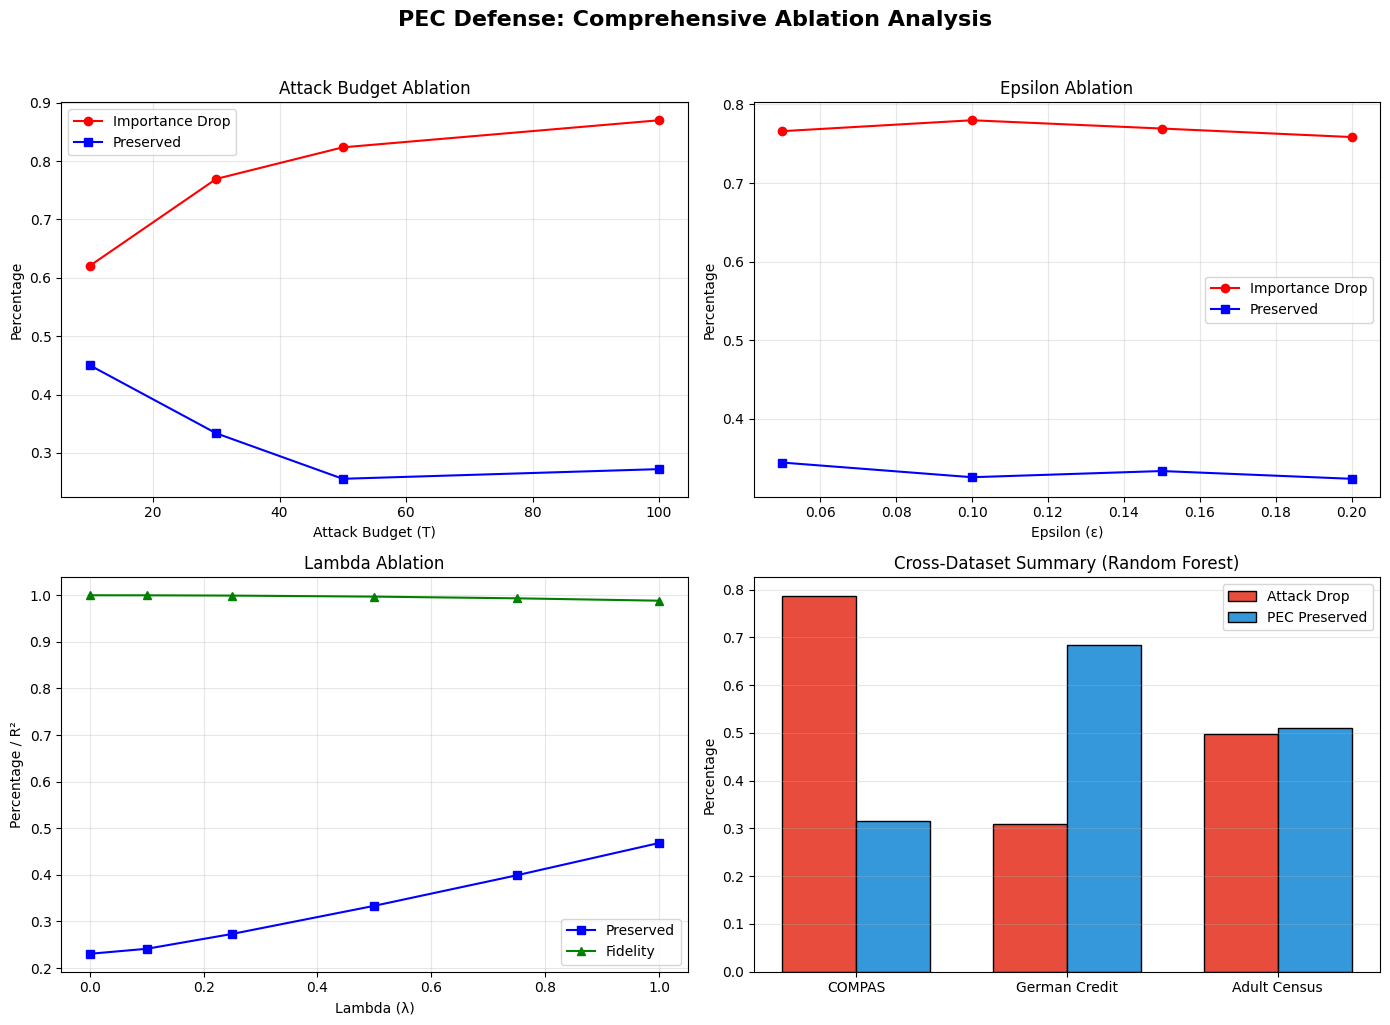

✅ Visualization complete!


In [ ]:
# ============================================================
# সেল ১২: Visualization
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Attack Budget Ablation
axes[0, 0].plot([r['budget'] for r in budget_results],
                [r['importance_drop'] for r in budget_results], 'r-o', label='Importance Drop')
axes[0, 0].plot([r['budget'] for r in budget_results],
                [r['importance_preserved'] for r in budget_results], 'b-s', label='Preserved')
axes[0, 0].set_xlabel('Attack Budget (T)')
axes[0, 0].set_ylabel('Percentage')
axes[0, 0].set_title('Attack Budget Ablation')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Plot 2: Epsilon Ablation
axes[0, 1].plot([r['epsilon'] for r in epsilon_results],
                [r['importance_drop'] for r in epsilon_results], 'r-o', label='Importance Drop')
axes[0, 1].plot([r['epsilon'] for r in epsilon_results],
                [r['importance_preserved'] for r in epsilon_results], 'b-s', label='Preserved')
axes[0, 1].set_xlabel('Epsilon (ε)')
axes[0, 1].set_ylabel('Percentage')
axes[0, 1].set_title('Epsilon Ablation')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Plot 3: Lambda Ablation
axes[1, 0].plot([r['lambda'] for r in lambda_results],
                [r['importance_preserved'] for r in lambda_results], 'b-s', label='Preserved')
axes[1, 0].plot([r['lambda'] for r in lambda_results],
                [r['fidelity'] for r in lambda_results], 'g-^', label='Fidelity')
axes[1, 0].set_xlabel('Lambda (λ)')
axes[1, 0].set_ylabel('Percentage / R²')
axes[1, 0].set_title('Lambda Ablation')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Plot 4: Cross-Dataset Summary
datasets = ['COMPAS', 'German Credit', 'Adult Census']
rf_drops = [np.mean([r['importance_drop'] for r in all_results if r['dataset']==d and r['model']=='Random Forest']) for d in datasets]
rf_pres = [np.mean([r['importance_preserved'] for r in all_results if r['dataset']==d and r['model']=='Random Forest']) for d in datasets]
x = np.arange(len(datasets))
width = 0.35
axes[1, 1].bar(x - width/2, rf_drops, width, label='Attack Drop', color='#e74c3c', edgecolor='black')
axes[1, 1].bar(x + width/2, rf_pres, width, label='PEC Preserved', color='#3498db', edgecolor='black')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(datasets)
axes[1, 1].set_ylabel('Percentage')
axes[1, 1].set_title('Cross-Dataset Summary (Random Forest)')
axes[1, 1].legend()
axes[1, 1].grid(axis='y', alpha=0.3)

plt.suptitle('PEC Defense: Comprehensive Ablation Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("✅ Visualization complete!")

In [ ]:
# ============================================================
# সেল ১৩: Statistical Significance Tests
# ============================================================
print("="*70)
print("📊 STATISTICAL SIGNIFICANCE TESTS")
print("="*70)

for dataset_name in ['COMPAS', 'German Credit', 'Adult Census']:
    rf_results = [r for r in all_results if r['dataset'] == dataset_name and r['model'] == 'Random Forest']

    if rf_results:
        orig_imps = [r['original_importance'] for r in rf_results]
        attack_imps = [r['attacked_importance'] for r in rf_results]
        defended_imps = [r['defended_importance'] for r in rf_results]

        # Paired t-test: Original vs Attacked
        t_attack, p_attack = ttest_rel(orig_imps, attack_imps)

        # Paired t-test: Attacked vs Defended
        t_def, p_def = ttest_rel(attack_imps, defended_imps)

        print(f"\n  {dataset_name}:")
        print(f"    Original vs Attacked: t={t_attack:.2f}, p={p_attack:.6f} "
              f"({'✅ Significant' if p_attack < 0.05 else '❌ Not Significant'})")
        print(f"    Attacked vs Defended: t={t_def:.2f}, p={p_def:.6f} "
              f"({'✅ Significant' if p_def < 0.05 else '❌ Not Significant'})")

print("\n✅ Statistical tests complete!")

📊 STATISTICAL SIGNIFICANCE TESTS

  COMPAS:
    Original vs Attacked: t=24.82, p=0.001619 (✅ Significant)
    Attacked vs Defended: t=-20.35, p=0.002406 (✅ Significant)

  German Credit:
    Original vs Attacked: t=8.71, p=0.012939 (✅ Significant)
    Attacked vs Defended: t=0.71, p=0.548863 (❌ Not Significant)

  Adult Census:
    Original vs Attacked: t=25.47, p=0.001538 (✅ Significant)
    Attacked vs Defended: t=-1.34, p=0.312428 (❌ Not Significant)

✅ Statistical tests complete!


📁 Creating paper_artifacts directory structure...
✅ Table 1: Dataset Summary saved
✅ Table 2: Main Results saved
✅ Table 3: Aggregated Summary saved
✅ Table 4: Attack Comparison saved
✅ Table 5: Model Comparison saved


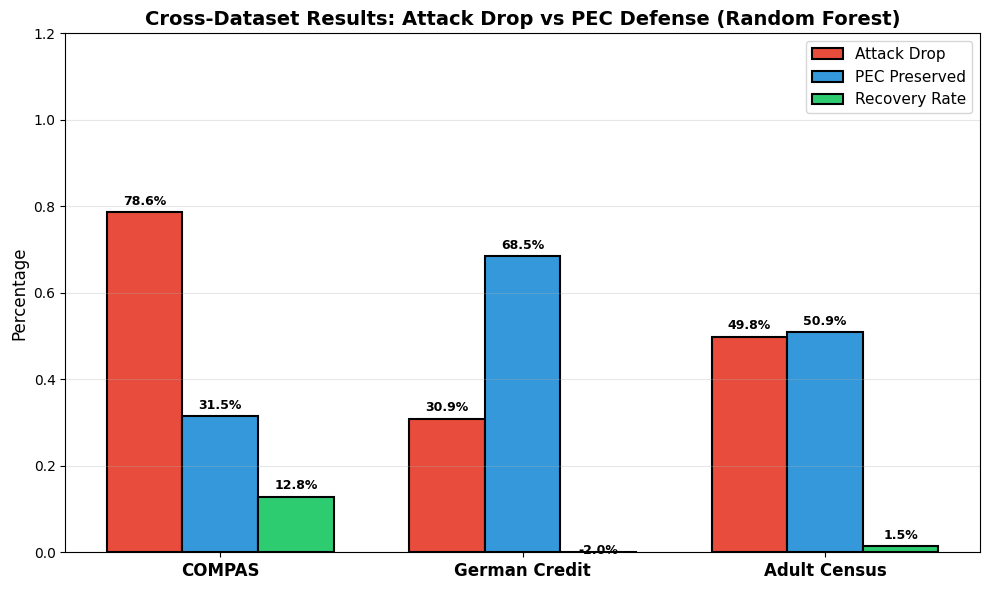

✅ Figure 1: Cross-Dataset Bar Chart saved


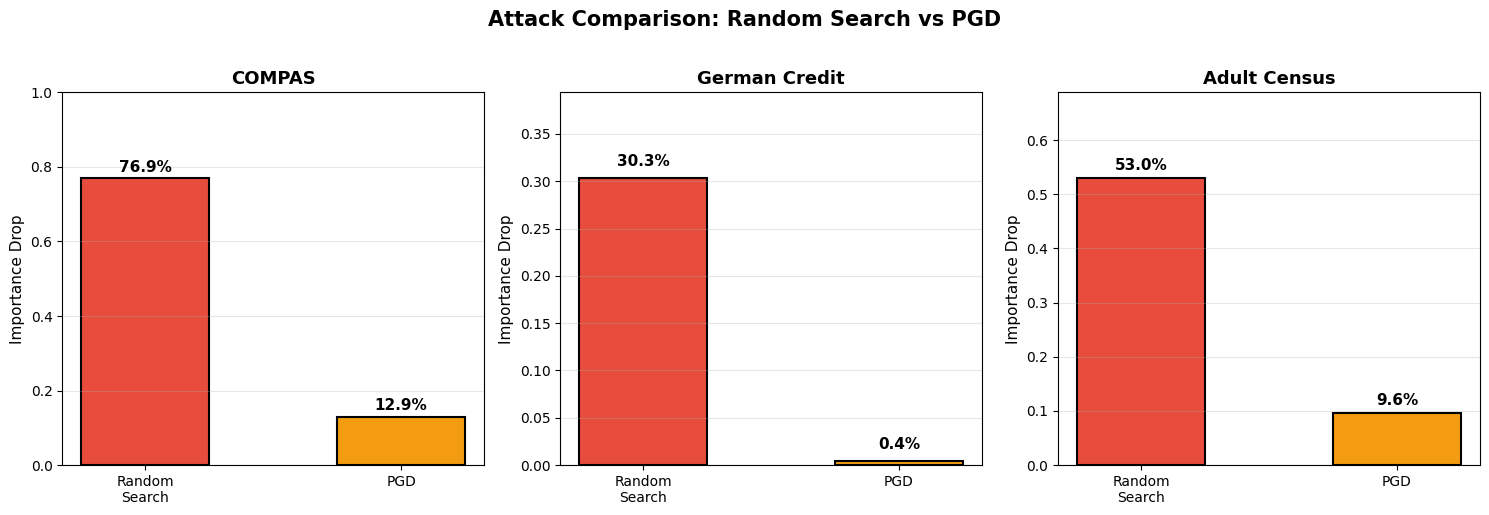

✅ Figure 2: Attack Comparison Plot saved


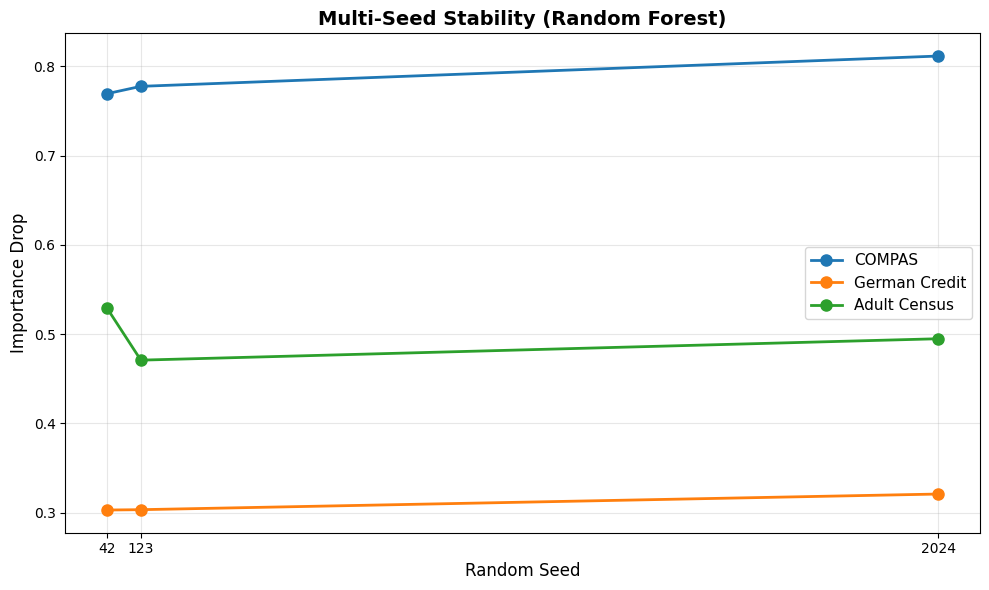

✅ Figure 3: Multi-Seed Stability Plot saved


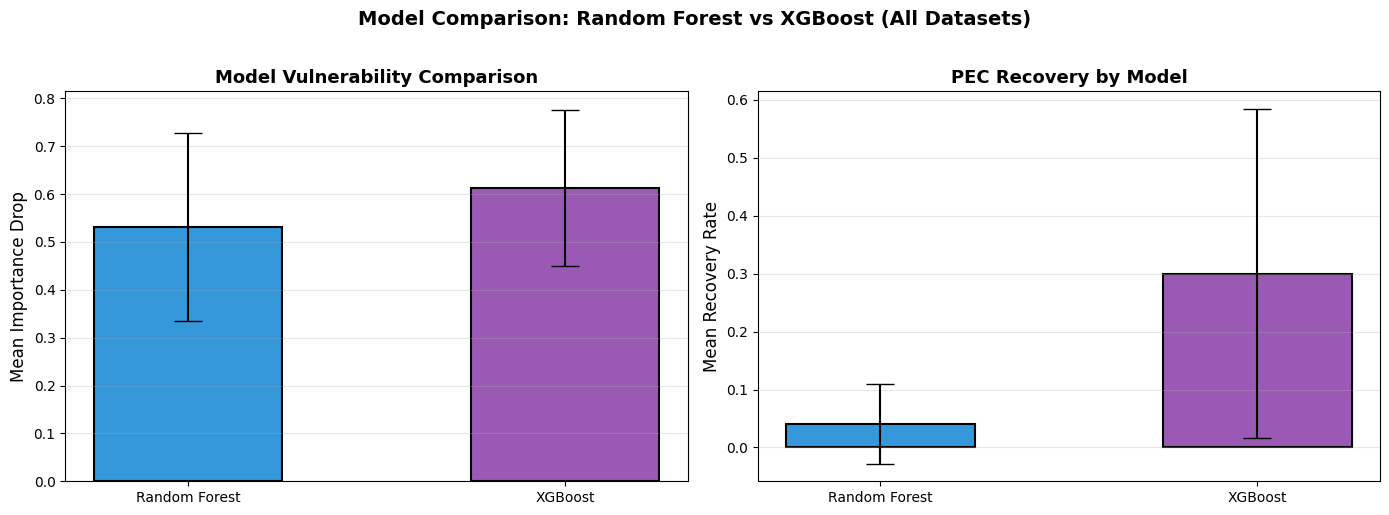

✅ Figure 4: Model Comparison Plot saved


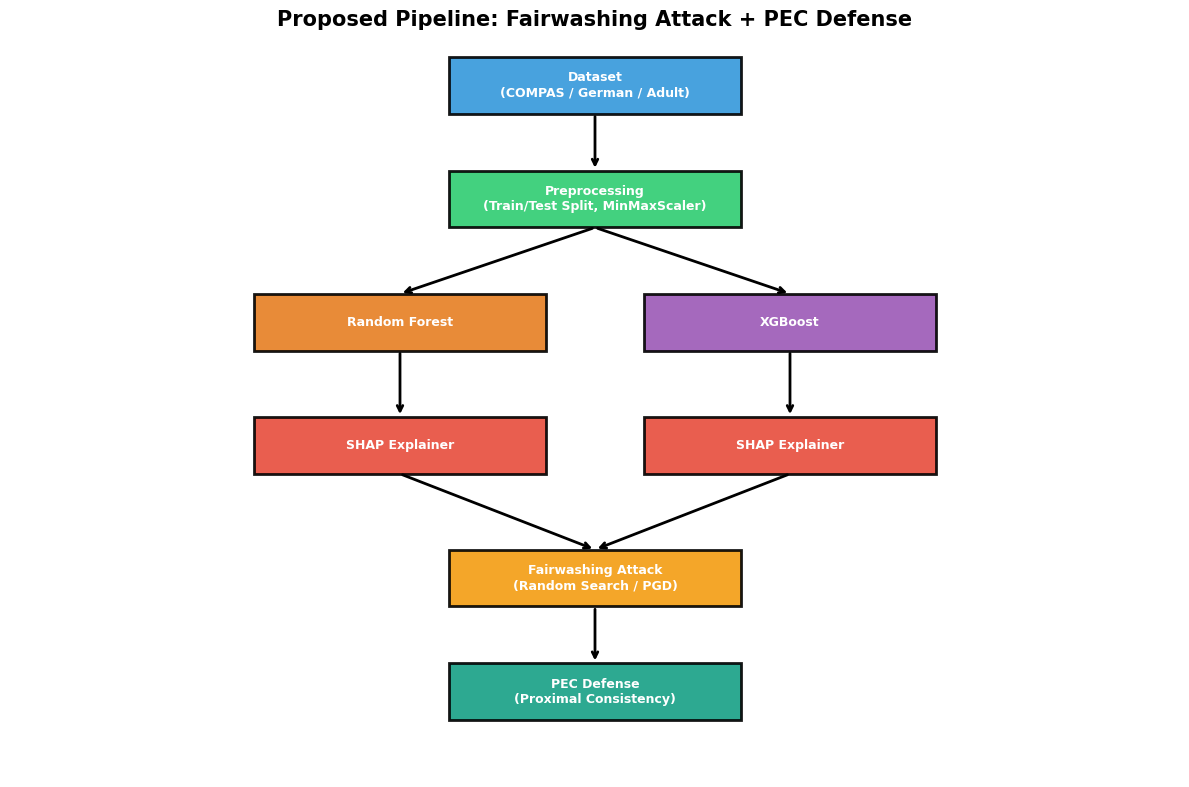

✅ Figure 5: Pipeline Diagram saved

📦 Creating ZIP file...
  Added: figures/figure4_model_comparison.pdf
  Added: figures/figure1_cross_dataset.png
  Added: figures/figure2_attack_comparison.png
  Added: figures/figure3_multi_seed.pdf
  Added: figures/figure5_pipeline.pdf
  Added: figures/figure2_attack_comparison.pdf
  Added: figures/figure4_model_comparison.png
  Added: figures/figure3_multi_seed.png
  Added: figures/figure5_pipeline.png
  Added: figures/figure1_cross_dataset.pdf
  Added: tables/table4_attack_comparison.csv
  Added: tables/table1_dataset_summary.csv
  Added: tables/table2_main_results.csv
  Added: tables/table5_model_comparison.csv
  Added: tables/table3_summary_mean_std.csv

✅ ZIP file created: paper_artifacts_complete.zip

📥 Downloading ZIP file...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ All paper artifacts generated and ready for download!

📋 Summary of generated files:
--------------------------------------------------
Tables:
  ✓ table1_dataset_summary.csv
  ✓ table2_main_results.csv
  ✓ table3_summary_mean_std.csv
  ✓ table4_attack_comparison.csv
  ✓ table5_model_comparison.csv

Figures:
  ✓ figure1_cross_dataset.pdf
  ✓ figure1_cross_dataset.png
  ✓ figure2_attack_comparison.pdf
  ✓ figure2_attack_comparison.png
  ✓ figure3_multi_seed.pdf
  ✓ figure3_multi_seed.png
  ✓ figure4_model_comparison.pdf
  ✓ figure4_model_comparison.png
  ✓ figure5_pipeline.pdf
  ✓ figure5_pipeline.png


In [ ]:
# ============================================================
# সেল: Generate All Paper Artifacts + Download ZIP
# ============================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import zipfile
import os

# Create output directory
os.makedirs('paper_artifacts/tables', exist_ok=True)
os.makedirs('paper_artifacts/figures', exist_ok=True)

print("📁 Creating paper_artifacts directory structure...")

# ============================================================
# TABLE 1: Dataset Summary
# ============================================================
table1_data = {
    'Dataset': ['COMPAS', 'German Credit', 'Adult Census'],
    'Samples': ['7,164', '1,000', '5,000'],
    'Features': [9, 15, 12],
    'Protected Attribute': ['Race', 'Age', 'Race, Sex'],
    'Domain': ['Criminal Justice', 'Finance', 'Demographics']
}
df_table1 = pd.DataFrame(table1_data)
df_table1.to_csv('paper_artifacts/tables/table1_dataset_summary.csv', index=False)

print("✅ Table 1: Dataset Summary saved")

# ============================================================
# TABLE 2: Main Results - Cross-Dataset Multi-Seed
# ============================================================
all_results_clean = []
for r in all_results:
    all_results_clean.append({
        'Dataset': r['dataset'],
        'Model': r['model'],
        'Seed': r['seed'],
        'Accuracy': r['accuracy'],
        'Importance_Drop': r['importance_drop'],
        'Importance_Preserved': r['importance_preserved'],
        'Recovery_Rate': r['recovery_rate'],
        'Fidelity_Original': r['fidelity_original'],
        'Fidelity_Defended': r['fidelity_defended'],
        'Attack_Success': r['attack_success_rate'],
        'Pred_Preserved': r['prediction_preservation']
    })

df_main = pd.DataFrame(all_results_clean)
df_main.to_csv('paper_artifacts/tables/table2_main_results.csv', index=False)

print("✅ Table 2: Main Results saved")

# ============================================================
# TABLE 3: Aggregated Mean ± Std Results
# ============================================================
summary_rows = []
for dataset in ['COMPAS', 'German Credit', 'Adult Census']:
    for model in ['Random Forest', 'XGBoost']:
        subset = df_main[(df_main['Dataset'] == dataset) & (df_main['Model'] == model)]
        if len(subset) > 0:
            summary_rows.append({
                'Dataset': dataset,
                'Model': model,
                'Accuracy': f"{subset['Accuracy'].mean():.4f} ± {subset['Accuracy'].std():.4f}",
                'Importance_Drop': f"{subset['Importance_Drop'].mean():.1%} ± {subset['Importance_Drop'].std():.1%}",
                'Importance_Preserved': f"{subset['Importance_Preserved'].mean():.1%} ± {subset['Importance_Preserved'].std():.1%}",
                'Recovery_Rate': f"{subset['Recovery_Rate'].mean():.1%} ± {subset['Recovery_Rate'].std():.1%}",
                'Fidelity_Defended': f"{subset['Fidelity_Defended'].mean():.4f}"
            })

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv('paper_artifacts/tables/table3_summary_mean_std.csv', index=False)

print("✅ Table 3: Aggregated Summary saved")

# ============================================================
# TABLE 4: Attack Comparison (Random vs PGD)
# ============================================================
attack_comparison_rows = []
for r in attack_comparison_results:
    attack_comparison_rows.append({
        'Dataset': r['dataset'],
        'Attack_Type': r['attack_type'],
        'Importance_Drop': f"{r['importance_drop']:.1%}",
        'Importance_Preserved': f"{r['importance_preserved']:.1%}",
        'Attack_Success': f"{r['attack_success_rate']:.1%}",
        'Pred_Preserved': f"{r['prediction_preservation']:.1%}"
    })

df_attack = pd.DataFrame(attack_comparison_rows)
df_attack.to_csv('paper_artifacts/tables/table4_attack_comparison.csv', index=False)

print("✅ Table 4: Attack Comparison saved")

# ============================================================
# TABLE 5: Model Comparison (RF vs XGBoost, COMPAS)
# ============================================================
model_comp_rows = []
for r in all_results:
    if r['dataset'] == 'COMPAS' and r['seed'] == 42:
        model_comp_rows.append({
            'Model': r['model'],
            'Accuracy': f"{r['accuracy']:.4f}",
            'Importance_Drop': f"{r['importance_drop']:.1%}",
            'Importance_Preserved': f"{r['importance_preserved']:.1%}",
            'Recovery_Rate': f"{r['recovery_rate']:.1%}",
            'Fidelity_Original': f"{r['fidelity_original']:.4f}",
            'Fidelity_Defended': f"{r['fidelity_defended']:.4f}"
        })

df_model_comp = pd.DataFrame(model_comp_rows)
df_model_comp.to_csv('paper_artifacts/tables/table5_model_comparison.csv', index=False)

print("✅ Table 5: Model Comparison saved")

# ============================================================
# FIGURE 1: Cross-Dataset Bar Chart
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))

datasets = ['COMPAS', 'German Credit', 'Adult Census']
rf_drops = [np.mean([r['importance_drop'] for r in all_results if r['dataset']==d and r['model']=='Random Forest']) for d in datasets]
rf_pres = [np.mean([r['importance_preserved'] for r in all_results if r['dataset']==d and r['model']=='Random Forest']) for d in datasets]
rf_rec = [np.mean([r['recovery_rate'] for r in all_results if r['dataset']==d and r['model']=='Random Forest']) for d in datasets]

x = np.arange(len(datasets))
width = 0.25

bars1 = ax.bar(x - width, rf_drops, width, label='Attack Drop', color='#e74c3c', edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x, rf_pres, width, label='PEC Preserved', color='#3498db', edgecolor='black', linewidth=1.5)
bars3 = ax.bar(x + width, rf_rec, width, label='Recovery Rate', color='#2ecc71', edgecolor='black', linewidth=1.5)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.1%}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(datasets, fontsize=12, fontweight='bold')
ax.set_ylabel('Percentage', fontsize=12)
ax.set_title('Cross-Dataset Results: Attack Drop vs PEC Defense (Random Forest)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 1.2)

plt.tight_layout()
plt.savefig('paper_artifacts/figures/figure1_cross_dataset.pdf', bbox_inches='tight', dpi=300)
plt.savefig('paper_artifacts/figures/figure1_cross_dataset.png', bbox_inches='tight', dpi=300)
plt.show()

print("✅ Figure 1: Cross-Dataset Bar Chart saved")

# ============================================================
# FIGURE 2: Attack Comparison Plot
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, dataset_name in enumerate(datasets):
    ax = axes[idx]
    random_drop = [r['importance_drop'] for r in attack_comparison_results
                   if r['dataset']==dataset_name and r['attack_type']=='Random Search']
    pgd_drop = [r['importance_drop'] for r in attack_comparison_results
                if r['dataset']==dataset_name and r['attack_type']=='PGD']

    if random_drop and pgd_drop:
        values = [random_drop[0], pgd_drop[0]]
        bars = ax.bar(['Random\nSearch', 'PGD'], values,
                      color=['#e74c3c', '#f39c12'], edgecolor='black', linewidth=1.5, width=0.5)

        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                    f'{val:.1%}', ha='center', va='bottom', fontsize=11, fontweight='bold')

        ax.set_title(dataset_name, fontsize=13, fontweight='bold')
        ax.set_ylabel('Importance Drop', fontsize=11)
        ax.set_ylim(0, max(values) * 1.3)
        ax.grid(axis='y', alpha=0.3)

plt.suptitle('Attack Comparison: Random Search vs PGD', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('paper_artifacts/figures/figure2_attack_comparison.pdf', bbox_inches='tight', dpi=300)
plt.savefig('paper_artifacts/figures/figure2_attack_comparison.png', bbox_inches='tight', dpi=300)
plt.show()

print("✅ Figure 2: Attack Comparison Plot saved")

# ============================================================
# FIGURE 3: Multi-Seed Stability Plot
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))

seeds = CONFIG['random_seeds']
for dataset_name in datasets:
    drops = []
    for seed in seeds:
        subset = [r for r in all_results if r['dataset']==dataset_name and r['model']=='Random Forest' and r['seed']==seed]
        if subset:
            drops.append(subset[0]['importance_drop'])
    if drops:
        ax.plot(seeds, drops, 'o-', linewidth=2, markersize=8, label=dataset_name)

ax.set_xlabel('Random Seed', fontsize=12)
ax.set_ylabel('Importance Drop', fontsize=12)
ax.set_title('Multi-Seed Stability (Random Forest)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
ax.set_xticks(seeds)

plt.tight_layout()
plt.savefig('paper_artifacts/figures/figure3_multi_seed.pdf', bbox_inches='tight', dpi=300)
plt.savefig('paper_artifacts/figures/figure3_multi_seed.png', bbox_inches='tight', dpi=300)
plt.show()

print("✅ Figure 3: Multi-Seed Stability Plot saved")

# ============================================================
# FIGURE 4: Model Comparison Plot (RF vs XGBoost)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Importance Drop by Model
ax = axes[0]
rf_drops_all = [r['importance_drop'] for r in all_results if r['model']=='Random Forest']
xgb_drops_all = [r['importance_drop'] for r in all_results if r['model']=='XGBoost']

if rf_drops_all and xgb_drops_all:
    x = np.arange(2)
    means = [np.mean(rf_drops_all), np.mean(xgb_drops_all)]
    stds = [np.std(rf_drops_all), np.std(xgb_drops_all)]

    bars = ax.bar(['Random Forest', 'XGBoost'], means, yerr=stds, capsize=10,
                  color=['#3498db', '#9b59b6'], edgecolor='black', linewidth=1.5, width=0.5)
    ax.set_ylabel('Mean Importance Drop', fontsize=12)
    ax.set_title('Model Vulnerability Comparison', fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

# Plot 2: PEC Recovery by Model
ax = axes[1]
rf_rec_all = [r['recovery_rate'] for r in all_results if r['model']=='Random Forest']
xgb_rec_all = [r['recovery_rate'] for r in all_results if r['model']=='XGBoost']

if rf_rec_all and xgb_rec_all:
    x = np.arange(2)
    means = [np.mean(rf_rec_all), np.mean(xgb_rec_all)]
    stds = [np.std(rf_rec_all), np.std(xgb_rec_all)]

    bars = ax.bar(['Random Forest', 'XGBoost'], means, yerr=stds, capsize=10,
                  color=['#3498db', '#9b59b6'], edgecolor='black', linewidth=1.5, width=0.5)
    ax.set_ylabel('Mean Recovery Rate', fontsize=12)
    ax.set_title('PEC Recovery by Model', fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Model Comparison: Random Forest vs XGBoost (All Datasets)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('paper_artifacts/figures/figure4_model_comparison.pdf', bbox_inches='tight', dpi=300)
plt.savefig('paper_artifacts/figures/figure4_model_comparison.png', bbox_inches='tight', dpi=300)
plt.show()

print("✅ Figure 4: Model Comparison Plot saved")

# ============================================================
# FIGURE 5: Pipeline Diagram
# ============================================================
fig, ax = plt.subplots(figsize=(12, 8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis('off')

boxes = [
    (4.5, 7, 3, 0.6, 'Dataset\n(COMPAS / German / Adult)', '#3498db'),
    (4.5, 5.8, 3, 0.6, 'Preprocessing\n(Train/Test Split, MinMaxScaler)', '#2ecc71'),
    (2.5, 4.5, 3, 0.6, 'Random Forest', '#e67e22'),
    (6.5, 4.5, 3, 0.6, 'XGBoost', '#9b59b6'),
    (2.5, 3.2, 3, 0.6, 'SHAP Explainer', '#e74c3c'),
    (6.5, 3.2, 3, 0.6, 'SHAP Explainer', '#e74c3c'),
    (4.5, 1.8, 3, 0.6, 'Fairwashing Attack\n(Random Search / PGD)', '#f39c12'),
    (4.5, 0.6, 3, 0.6, 'PEC Defense\n(Proximal Consistency)', '#16a085'),
]

for (x, y, w, h, text, color) in boxes:
    rect = plt.Rectangle((x, y), w, h, facecolor=color, edgecolor='black', linewidth=2, alpha=0.9)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=9, fontweight='bold', color='white')

arrows = [
    (6, 7, 6, 6.4),
    (6, 5.8, 4, 5.1),
    (6, 5.8, 8, 5.1),
    (4, 4.5, 4, 3.8),
    (8, 4.5, 8, 3.8),
    (4, 3.2, 6, 2.4),
    (8, 3.2, 6, 2.4),
    (6, 1.8, 6, 1.2),
]

for (x1, y1, x2, y2) in arrows:
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', lw=2, color='black'))

ax.set_title('Proposed Pipeline: Fairwashing Attack + PEC Defense', fontsize=15, fontweight='bold', y=0.98)

plt.tight_layout()
plt.savefig('paper_artifacts/figures/figure5_pipeline.pdf', bbox_inches='tight', dpi=300)
plt.savefig('paper_artifacts/figures/figure5_pipeline.png', bbox_inches='tight', dpi=300)
plt.show()

print("✅ Figure 5: Pipeline Diagram saved")

# ============================================================
# CREATE ZIP FILE
# ============================================================
print("\n📦 Creating ZIP file...")

zip_filename = 'paper_artifacts_complete.zip'
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk('paper_artifacts'):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, 'paper_artifacts')
            zipf.write(file_path, arcname)
            print(f"  Added: {arcname}")

print(f"\n✅ ZIP file created: {zip_filename}")

# ============================================================
# DOWNLOAD ZIP — FIXED
# ============================================================
print("\n📥 Downloading ZIP file...")
from google.colab import files as colab_files
colab_files.download(zip_filename)

print("\n✅ All paper artifacts generated and ready for download!")
print("\n📋 Summary of generated files:")
print("-" * 50)
print("Tables:")
for f in sorted(os.listdir('paper_artifacts/tables')):
    print(f"  ✓ {f}")
print("\nFigures:")
for f in sorted(os.listdir('paper_artifacts/figures')):
    print(f"  ✓ {f}")